# 06 - Prediction intervals

A point forecast ("1.2 s faster than base pace") hides how sure the model is. This notebook produces ranges and, more importantly, checks them. An 80% interval should contain the true value about 80% of the time, on races the model hasn't seen.

I try two methods. Both are conformal, so the coverage promise doesn't depend on the model being right.

- Constant width: the gradient-boosting forecast plus or minus a fixed margin.
- CQR (conformalized quantile regression): quantile models whose width adapts to the input, widened by a calibrated margin.

Calibration scores come from cross-validation grouped by race inside the 2022 and 2023 training seasons, so no score comes from a model that saw its own race. I evaluate on 2024, which none of this has seen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from f1lab.features import prepare, split
from f1lab.models import gbm_features
from f1lab.conformal import CQR, ConstantWidth, coverage, mean_width

raw = pd.read_parquet("../data/laps.parquet")
clean = pd.read_parquet("../data/laps_clean.parquet")
train, val = split(prepare(raw, clean), "dev")
tracks = sorted(train["track"].unique())
X, Xv = gbm_features(train, tracks), gbm_features(val, tracks)
y, yv = train["delta_s"], val["delta_s"]
groups = (train["season"].astype(str) + "-" + train["round"].astype(str)).values
val_race = val["track"] + " " + val["round"].astype(str)

## Coverage on 2024

In [2]:
fitted = {}
rows = []
for level in (0.8, 0.9):
    for name, cls in (("constant width", ConstantWidth), ("CQR", CQR)):
        m = cls(1 - level).fit(X, y, groups)
        lo, hi = m.predict(Xv)
        fitted[(name, level)] = (lo, hi)
        rows.append({"target": f"{level:.0%}", "method": name,
                     "coverage": coverage(yv, lo, hi), "mean width (s)": mean_width(lo, hi)})
pd.DataFrame(rows).set_index(["target", "method"]).round(3)

coverage  mean width (s)
target method                                  
80%    constant width     0.783           1.610
       CQR                0.803           1.781
90%    constant width     0.895           2.296
       CQR                0.901           2.544

Both methods land close to the target on a season they never saw. CQR hits it (0.803 at 80%, 0.901 at 90%). The constant-width interval falls slightly short (0.783 and 0.895). CQR pays for that with intervals about 11% wider (1.78 s against 1.61 s at 80%).

## Reliability: does nominal match actual across levels?

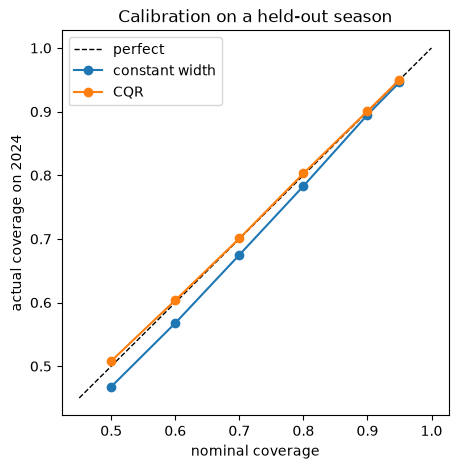

,constant width,CQR
50%,0.468,0.508
60%,0.568,0.604
70%,0.675,0.701
80%,0.783,0.803
90%,0.895,0.901
95%,0.946,0.950


In [3]:
levels = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
curve = {"constant width": [], "CQR": []}
for level in levels:
    for name, cls in (("constant width", ConstantWidth), ("CQR", CQR)):
        lo, hi = cls(1 - level).fit(X, y, groups).predict(Xv)
        curve[name].append(coverage(yv, lo, hi))
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0.45, 1], [0.45, 1], "k--", lw=1, label="perfect")
for name, vals in curve.items():
    ax.plot(levels, vals, marker="o", label=name)
ax.set_xlabel("nominal coverage"); ax.set_ylabel("actual coverage on 2024")
ax.legend(); ax.set_title("Calibration on a held-out season")
plt.show()
pd.DataFrame(curve, index=[f"{l:.0%}" for l in levels]).round(3)

CQR is within 0.01 of the claimed level at every level I tested, from 50% to 95%. Constant width under-covers, most at the lower levels (0.468 for a claimed 50%) and catches up at the top (0.946 for 95%). Letting the width follow the input is worth the extra width.

## Coverage is not the same in every race

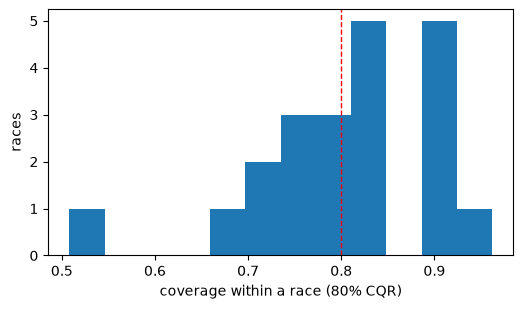

,coverage,above,below,spread,laps
race,,,,,
Monte Carlo 8,0.51,0.15,0.34,1.98,1187
Shanghai 5,0.68,0.24,0.08,2.42,778
Baku 17,0.72,0.13,0.15,1.90,888
Zandvoort 15,0.73,0.20,0.06,0.92,1354
Lusail 23,0.74,0.07,0.19,1.41,717
Suzuka 4,0.76,0.13,0.11,1.38,774


In [4]:
lo, hi = fitted[("CQR", 0.8)]
res = val.assign(lo=lo, hi=hi)
res["hit"] = (res["delta_s"] >= res["lo"]) & (res["delta_s"] <= res["hi"])
res["above"] = res["delta_s"] > res["hi"]
res["below"] = res["delta_s"] < res["lo"]
res["race"] = val_race
per_race = res.groupby("race").agg(coverage=("hit", "mean"), above=("above", "mean"), below=("below", "mean"),
                                   spread=("delta_s", "std"), laps=("hit", "size"))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(per_race["coverage"], bins=12)
ax.axvline(0.8, color="red", ls="--", lw=1)
ax.set_xlabel("coverage within a race (80% CQR)"); ax.set_ylabel("races")
plt.show()
per_race.sort_values("coverage").head(6).round(2)

In [5]:
bad = per_race.index[per_race["coverage"] < 0.7]
print(f"races under 70% coverage: {len(bad)} of {len(per_race)}")
print(f"overall coverage {res['hit'].mean():.3f}; without those races {res[~res['race'].isin(bad)]['hit'].mean():.3f}")
print(f"misses above the interval {res['above'].mean():.3f}, below {res['below'].mean():.3f} (ideal 0.100 each)")

races under 70% coverage: 2 of 21
overall coverage 0.803; without those races 0.827
misses above the interval 0.102, below 0.095 (ideal 0.100 each)


Overall coverage is on target (0.803) and the misses are balanced (10.2% above, 9.5% below, ideally 10% each). But coverage varies by race: two of 21 fall under 70%, Monte Carlo (0.51) and Shanghai (0.68). Without them overall coverage is 0.827, so the method is slightly conservative on typical races and fails on unusual ones. Both are tracks with no training data, which the next section confirms.

## Other subgroups

In [6]:
stage = pd.cut(1 - res["laps_remaining"] / res["race_laps"], [0, .25, .5, .75, 1])
by_stage = res.groupby(stage, observed=True).agg(coverage=("hit", "mean"), width=("hi", "size"))
by_stage["width (s)"] = (res["hi"] - res["lo"]).groupby(stage, observed=True).mean()
print(by_stage[["coverage", "width (s)"]].round(3).to_string())
print()
print("by compound:", res.groupby("compound")["hit"].mean().round(3).to_dict())
unseen = ~res["track"].isin(train["track"].unique())
print("tracks with no training data:", sorted(res.loc[unseen, "track"].unique()), f"({unseen.sum()} laps)")
print(f"coverage at unseen tracks: {res.loc[unseen, 'hit'].mean():.3f} | at seen tracks: {res.loc[~unseen, 'hit'].mean():.3f}")
print(res[unseen].groupby("track")["hit"].mean().round(3).to_dict())

             coverage  width (s)
(0.0, 0.25]     0.809      2.012
(0.25, 0.5]     0.827      1.715
(0.5, 0.75]     0.818      1.498
(0.75, 1.0]     0.762      1.907

by compound: {'HARD': 0.801, 'MEDIUM': 0.8, 'SOFT': 0.837}
tracks with no training data: ['Imola', 'Monte Carlo', 'Shanghai'] (3130 laps)
coverage at unseen tracks: 0.647 | at seen tracks: 0.830
{'Imola': 0.767, 'Monte Carlo': 0.508, 'Shanghai': 0.681}


Coverage is steady by compound (0.80 to 0.84) and through the race (0.81 to 0.83), apart from the final quarter, which falls short (0.762). The clearest pattern is the track. Coverage is 0.830 at tracks the model has seen and 0.647 at the three it hasn't (Imola 0.767, Shanghai 0.681, Monte Carlo 0.508). The interval is a little conservative at familiar tracks and optimistic at new ones.

Could I fix this by making the cross-validation folds hold out whole tracks instead of whole races, so the calibration scores reflect the unfamiliar-track case?

In [7]:
by_track = train["track"].values
rows = []
for name, g in (("folds grouped by race", groups), ("folds grouped by track", by_track)):
    lo_g, hi_g = CQR(0.2).fit(X, y, g).predict(Xv)
    hit = ((yv.values >= lo_g) & (yv.values <= hi_g))
    rows.append({"calibration": name, "coverage (all)": hit.mean(), "seen tracks": hit[~unseen].mean(),
                 "unseen tracks": hit[unseen].mean(), "mean width (s)": (hi_g - lo_g).mean()})
pd.DataFrame(rows).set_index("calibration").round(3)

,coverage (all),seen tracks,unseen tracks,mean width (s)
calibration,,,,
folds grouped by race,0.803,0.830,0.647,1.781
folds grouped by track,0.815,0.842,0.661,1.830


It barely helps. Coverage at unseen tracks moves from about 0.65 to 0.66 and the intervals get about 3% wider. So the shortfall isn't a calibration-fold problem. Unseen tracks are just harder than the average track, and the interval doesn't widen for them because the model has no way of knowing the track is unfamiliar. I haven't solved this. The intervals can be trusted at tracks that are in the training data and are optimistic at new ones.

## What an interval looks like

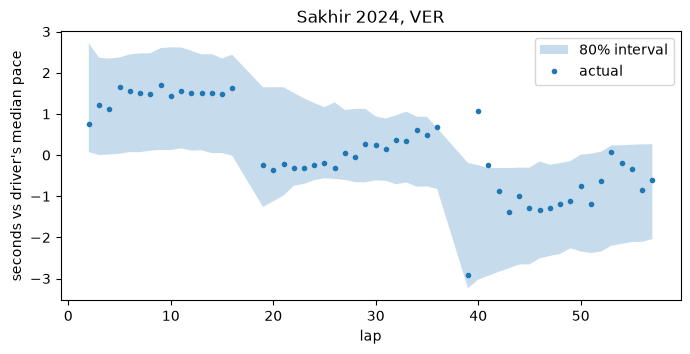

coverage for this driver-race: 0.94 over 52 laps


In [8]:
one = res[(res["track"] == "Sakhir") & (res["driver"] == "VER")].sort_values("lap_number")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.fill_between(one["lap_number"], one["lo"], one["hi"], alpha=0.25, label="80% interval")
ax.plot(one["lap_number"], one["delta_s"], "o", ms=3, label="actual")
ax.set_xlabel("lap"); ax.set_ylabel("seconds vs driver's median pace")
ax.set_title("Sakhir 2024, VER"); ax.legend()
plt.show()
print(f"coverage for this driver-race: {one['hit'].mean():.2f} over {len(one)} laps")

This driver-race happens to be well covered (0.94). It's meant to show what an interval looks like, not a typical case.

## Where that leaves me

- CQR intervals match their claimed level on a held-out season (80% claimed, 80.3% observed; 90% claimed, 90.1% observed), at about 11% extra width over a simple constant margin.
- Coverage is an average. It's conservative at tracks seen in training (0.83 for a claimed 0.80) and optimistic at unseen ones (0.65). Retraining the folds by track didn't fix that.
- The last quarter of a race is also under-covered (0.76).
- For the simulator, I treat these ranges as reliable for tracks in the training data and as a lower bound on the real uncertainty for new ones.